# Problem Statement and Objectives
This project aims to build a predictive model for house prices using the provided dataset. The objectives are:
1. Conduct Exploratory Data Analysis (EDA) to understand the data.
2. Preprocess the data, including handling missing values, encoding categorical variables, and scaling features.
3. Train baseline predictive models and optimize them for better performance.
4. Evaluate model performance using appropriate metrics.
5. Explain the model results and analyze feature importance.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
import lightgbm as lgb
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import shap
from sklearn.model_selection import GridSearchCV

In [ ]:
# Project-level parameters to avoid hardcoded values
DATA_FILE = 'AmesHousing.csv'
RANDOM_STATE = 42
TEST_SIZE = 0.2

In [ ]:
# Load the dataset
data = pd.read_csv(DATA_FILE)

In [ ]:
# Check for missing values
missing_values = data.isnull().sum()
# Handle missing values
# Fill numeric columns with the median
numeric_columns = data.select_dtypes(include=['number']).columns
data[numeric_columns] = data[numeric_columns].fillna(data[numeric_columns].median())

# Fill categorical columns with the mode
categorical_columns = data.select_dtypes(include=['object']).columns
for col in categorical_columns:
    data[col].fillna(data[col].mode()[0], inplace=True)

# Validate handling of missing values (inspect interactively if needed)
remaining_missing_values = data.isnull().sum().sum()

C:\Users\mvpra\AppData\Local\Temp\ipykernel_19952\3992195336.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[col].fillna(data[col].mode()[0], inplace=True)


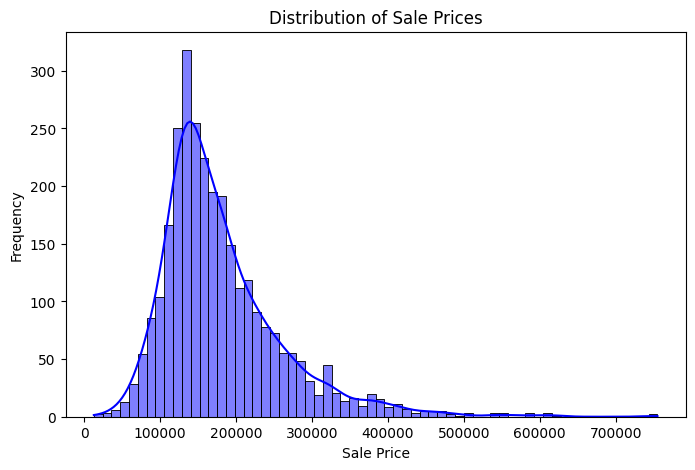

In [6]:
# Visualize the SalePrice distribution
plt.figure(figsize=(8, 5))
sns.histplot(data['SalePrice'], kde=True, color='blue')
plt.title("Distribution of Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

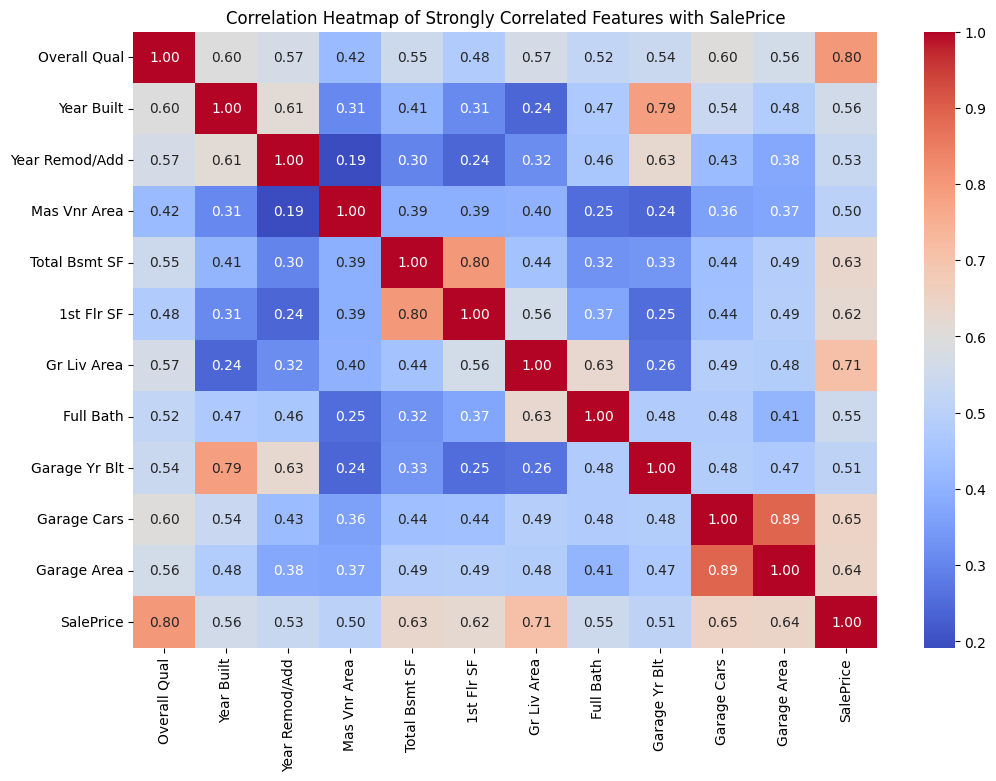

In [7]:
# Select only numeric columns
numeric_data = data.select_dtypes(include=['number'])

# Calculate correlation matrix
correlation_matrix = numeric_data.corr()

# Filter features strongly correlated with SalePrice (e.g., |correlation| > 0.5)
strong_corr_features = correlation_matrix['SalePrice'][
    (correlation_matrix['SalePrice'].abs() > 0.5)
].index

# Filter the correlation matrix for those features
filtered_corr = correlation_matrix.loc[strong_corr_features, strong_corr_features]

# Plot the heatmap for filtered features
plt.figure(figsize=(12, 8))
sns.heatmap(filtered_corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap of Strongly Correlated Features with SalePrice')
plt.show()


In [8]:
# Encode categorical variables
encoded_data = pd.get_dummies(data.drop(columns=['SalePrice']), drop_first=True)
target = data['SalePrice']

# Scale the features
scaler = StandardScaler()
encoded_data_scaled = scaler.fit_transform(encoded_data)
encoded_data_scaled_df = pd.DataFrame(encoded_data_scaled, columns=encoded_data.columns)


In [9]:
# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(encoded_data_scaled_df, target, test_size=TEST_SIZE, random_state=RANDOM_STATE)

In [10]:
# Baseline Random Forest model
rf_baseline = RandomForestRegressor(random_state=RANDOM_STATE)
rf_baseline.fit(X_train, y_train)
rf_pred_baseline = rf_baseline.predict(X_test)
rf_r2_baseline = r2_score(y_test, rf_pred_baseline)
rf_mse_baseline = mean_squared_error(y_test, rf_pred_baseline)
print("Baseline Random Forest Results:")
print("MSE:", rf_mse_baseline)
print("MAE:", mean_absolute_error(y_test, rf_pred_baseline))
print("R2 Score:", rf_r2_baseline)


Baseline Random Forest Results:
MSE: 710114660.799961
MAE: 15991.206655290101
R2 Score: 0.9114299450505985


In [11]:
# Optimized Random Forest model
rf_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=RANDOM_STATE), rf_params, cv=3, scoring='neg_mean_squared_error')
rf_grid.fit(X_train, y_train)
rf_optimized = rf_grid.best_estimator_
rf_pred_optimized = rf_optimized.predict(X_test)
rf_r2 = r2_score(y_test, rf_pred_optimized)
rf_mse = mean_squared_error(y_test, rf_pred_optimized)
print("Optimized Random Forest Results:")
print("MSE:", rf_mse)
print("MAE:", mean_absolute_error(y_test, rf_pred_optimized))
print("R2 Score:", rf_r2)

Optimized Random Forest Results:
MSE: 723823551.4585161
MAE: 15933.079301690177
R2 Score: 0.9097200842831052


100%|===================| 585/586 [02:50<00:00]        

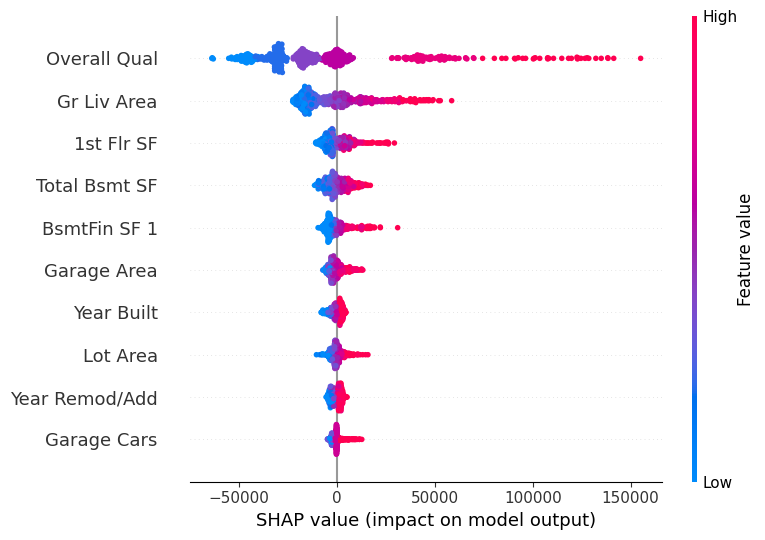

In [12]:
# SHAP explainability for Random Forest
explainer_rf = shap.Explainer(rf_optimized, X_test)
shap_values_rf = explainer_rf(X_test)
shap.summary_plot(shap_values_rf, X_test, max_display=10)

In [13]:
# Random Forest Predictions
new_data = X_test.iloc[:5]  # Example new data
predictions_rf = rf_optimized.predict(new_data)
print("Random Forest Predictions:", predictions_rf)

Random Forest Predictions: [184190.44       102578.85917344 193468.64391304 118252.16
 110806.79625966]


In [14]:
# Baseline XGBoost model
xgb_baseline = xgb.XGBRegressor(objective='reg:squarederror', random_state=RANDOM_STATE)
xgb_baseline.fit(X_train, y_train)
xgb_pred_baseline = xgb_baseline.predict(X_test)
xgb_r2_baseline = r2_score(y_test, xgb_pred_baseline)
xgb_mse_baseline = mean_squared_error(y_test, xgb_pred_baseline)
print("Baseline XGBoost Results:")
print("MSE:", xgb_mse_baseline)
print("MAE:", mean_absolute_error(y_test, xgb_pred_baseline))
print("R2 Score:", xgb_r2_baseline)

Baseline XGBoost Results:
MSE: 643308203.6381301
MAE: 15828.68686006826
R2 Score: 0.9197624921798706


In [15]:
# Optimized XGBoost model
xgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [3, 6, 10],
    'learning_rate': [0.01, 0.1, 0.2]
}
xgb_grid = GridSearchCV(xgb.XGBRegressor(objective='reg:squarederror', random_state=RANDOM_STATE), xgb_params, cv=3, scoring='neg_mean_squared_error')
xgb_grid.fit(X_train, y_train)
xgb_optimized = xgb_grid.best_estimator_
xgb_pred_optimized = xgb_optimized.predict(X_test)
xgb_r2 = r2_score(y_test, xgb_pred_optimized)
xgb_mse = mean_squared_error(y_test, xgb_pred_optimized)
print("Optimized XGBoost Results:")
print("MSE:", xgb_mse)
print("MAE:", mean_absolute_error(y_test, xgb_pred_optimized))
print("R2 Score:", xgb_r2)

Optimized XGBoost Results:
MSE: 544723297.4887583
MAE: 14460.673474829351
R2 Score: 0.9320586323738098


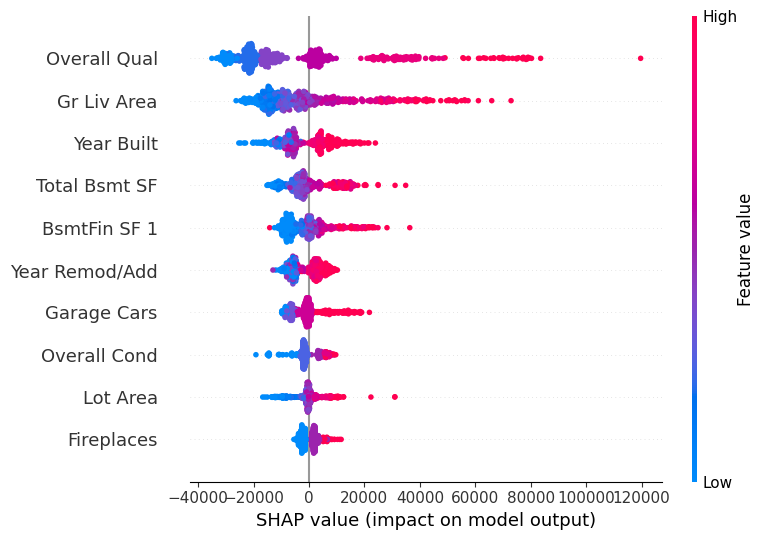

In [16]:
# SHAP explainability for XGBoost
explainer_xgb = shap.Explainer(xgb_optimized, X_test)
shap_values_xgb = explainer_xgb(X_test)
shap.summary_plot(shap_values_xgb, X_test, max_display=10)



In [ ]:
# XGBoost Predictions
predictions_xgb = xgb_optimized.predict(new_data)
print("XGBoost Predictions:", predictions_xgb)

XGBoost Predictions: [170533.44  105728.516 198301.73  126978.96  117005.734]


In [ ]:
# Baseline LightGBM model
lgb_baseline = lgb.LGBMRegressor(random_state=RANDOM_STATE)
lgb_baseline.fit(X_train, y_train)
lgb_pred_baseline = lgb_baseline.predict(X_test)
lgb_r2_baseline = r2_score(y_test, lgb_pred_baseline)
lgb_mse_baseline = mean_squared_error(y_test, lgb_pred_baseline)
print("Baseline LightGBM Results:")
print("MSE:", lgb_mse_baseline)
print("MAE:", mean_absolute_error(y_test, lgb_pred_baseline))
print("R2 Score:", lgb_r2_baseline)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.016207 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4385
[LightGBM] [Info] Number of data points in the train set: 2344, number of used features: 181
[LightGBM] [Info] Start training from score 178582.207765
Baseline LightGBM Results:
MSE: 707189384.1577932
MAE: 15338.928087002734
R2 Score: 0.9117948043152235


In [19]:
# Optimized LightGBM model
lgb_params = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, -1],
    'learning_rate': [0.01, 0.1]
}
lgb_grid = GridSearchCV(lgb.LGBMRegressor(random_state=RANDOM_STATE), lgb_params, cv=3, scoring='neg_mean_squared_error')
lgb_grid.fit(X_train, y_train)
lgb_optimized = lgb_grid.best_estimator_
lgb_pred_optimized = lgb_optimized.predict(X_test)
lgb_r2 = r2_score(y_test, lgb_pred_optimized)
lgb_mse = mean_squared_error(y_test, lgb_pred_optimized)
print("Optimized LightGBM Results:")
print("MSE:", lgb_mse)
print("MAE:", mean_absolute_error(y_test, lgb_pred_optimized))
print("R2 Score:", lgb_r2)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.012591 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4093
[LightGBM] [Info] Number of data points in the train set: 1562, number of used features: 164
[LightGBM] [Info] Start training from score 179552.485275
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.013786 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4109
[LightGBM] [Info] Number of data points in the train set: 1563, number of used features: 165
[LightGBM] [Info] Start training from score 177989.449136
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the over

c:\Users\mvpra\AppData\Local\Programs\Python\Python312\Lib\site-packages\numpy\ma\core.py:2846: RuntimeWarning: invalid value encountered in cast
  _data = np.array(data, dtype=dtype, copy=copy,


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.012738 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4385
[LightGBM] [Info] Number of data points in the train set: 2344, number of used features: 181
[LightGBM] [Info] Start training from score 178582.207765
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posi

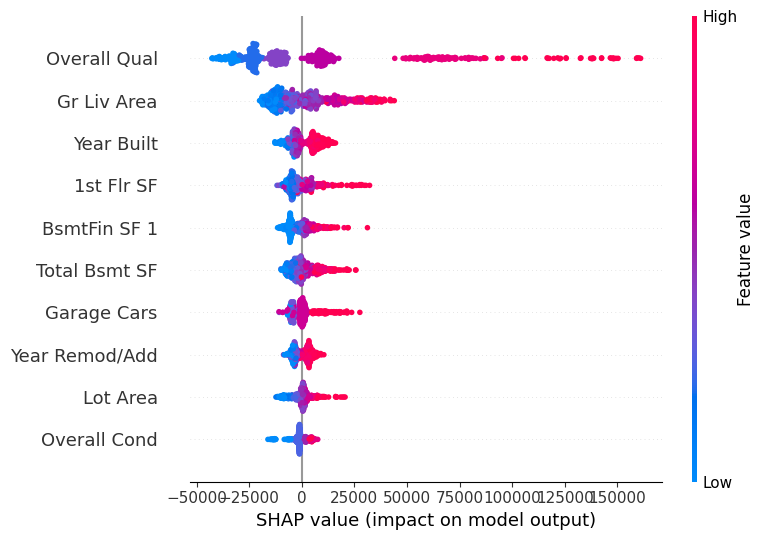

In [20]:
# SHAP explainability for LightGBM
explainer_lgb = shap.TreeExplainer(lgb_optimized)
shap_values_lgb = explainer_lgb.shap_values(X_test)
shap.summary_plot(shap_values_lgb, X_test, max_display=10)

In [ ]:
# LightGBM Predictions
predictions_lgb = lgb_optimized.predict(new_data)
print("LightGBM Predictions:", predictions_lgb)

LightGBM Predictions: [177112.87297743 105269.94085801 190459.44428329 123568.55272955
 112381.29378585]


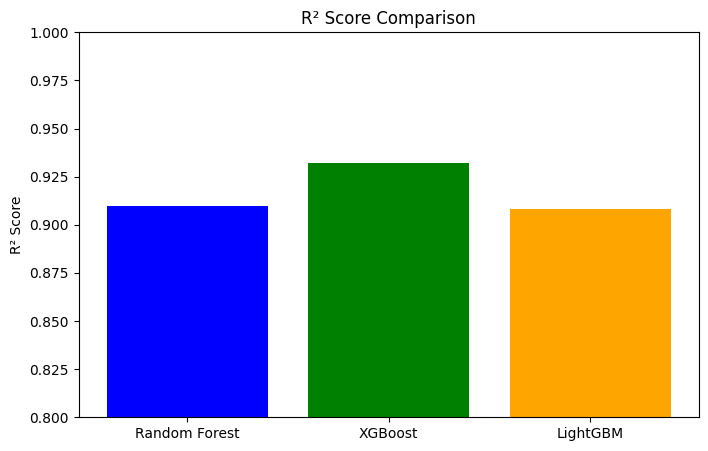

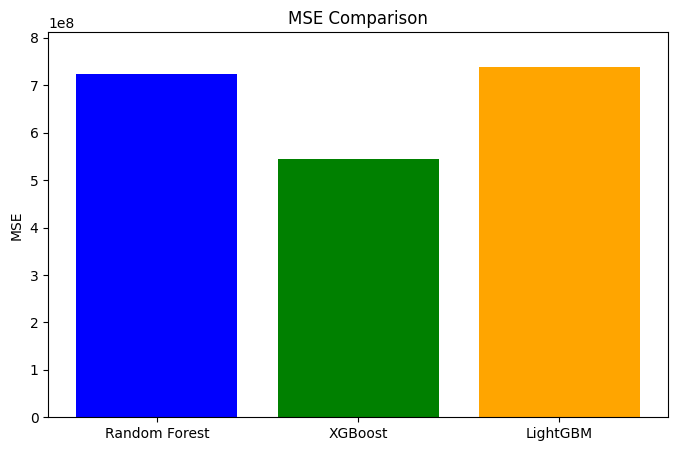

In [22]:
# Model Comparison
models = ['Random Forest', 'XGBoost', 'LightGBM']
r2_scores = [rf_r2, xgb_r2, lgb_r2]
mse_scores = [rf_mse, xgb_mse, lgb_mse]

# R² Score Comparison
plt.figure(figsize=(8, 5))
plt.bar(models, r2_scores, color=['blue', 'green', 'orange'])
plt.ylim(0.8, 1.0) 
plt.title("R² Score Comparison")
plt.ylabel("R² Score")
plt.show()

# MSE Comparison
plt.figure(figsize=(8, 5))
plt.bar(models, mse_scores, color=['blue', 'green', 'orange'])
plt.ylim(0, max(mse_scores) * 1.1)  
plt.title("MSE Comparison")
plt.ylabel("MSE")
plt.show()

In [ ]:
# Helper function to analyze and plot errors by a given feature
def analyze_prediction_error(feature, model_name, errors):
    """
    Analyze prediction errors by a given feature.
    """
    group_errors = errors.groupby(feature).mean().sort_values('Prediction_Error')

    plt.figure(figsize=(12, 6))
    group_errors['Prediction_Error'].plot(kind='bar', color='skyblue', alpha=0.8)
    plt.title(f"Prediction Error by {feature} ({model_name})")
    plt.ylabel("Mean Absolute Error")
    plt.xlabel(feature)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
# Fairness Analysis: Evaluate Bias in Model Predictions
def evaluate_fairness(feature, predictions, actuals, model_name):
    """
    Evaluate and visualize fairness by comparing prediction errors across different groups.
    """
    # Create a DataFrame for evaluation
    fairness_data = pd.DataFrame({
        feature: data.loc[X_test.index, feature],
        'Prediction': predictions,
        'Actual': actuals
    })
    fairness_data['Error'] = abs(fairness_data['Actual'] - fairness_data['Prediction'])

    # Group by the feature and calculate mean error
    group_stats = fairness_data.groupby(feature)['Error'].mean().sort_values()

    # Plot fairness analysis
    plt.figure(figsize=(10, 6))
    group_stats.plot(kind='bar', color='skyblue', alpha=0.8)
    plt.title(f"Fairness Analysis: Mean Prediction Error by {feature} ({model_name})")
    plt.ylabel("Mean Absolute Error")
    plt.xlabel(feature)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
# Features to analyze
features_to_analyze = ['Neighborhood', 'MS Zoning', 'House Style']

# Initialize test_data
test_data = data.iloc[X_test.index].copy()

Random Forest Analysis


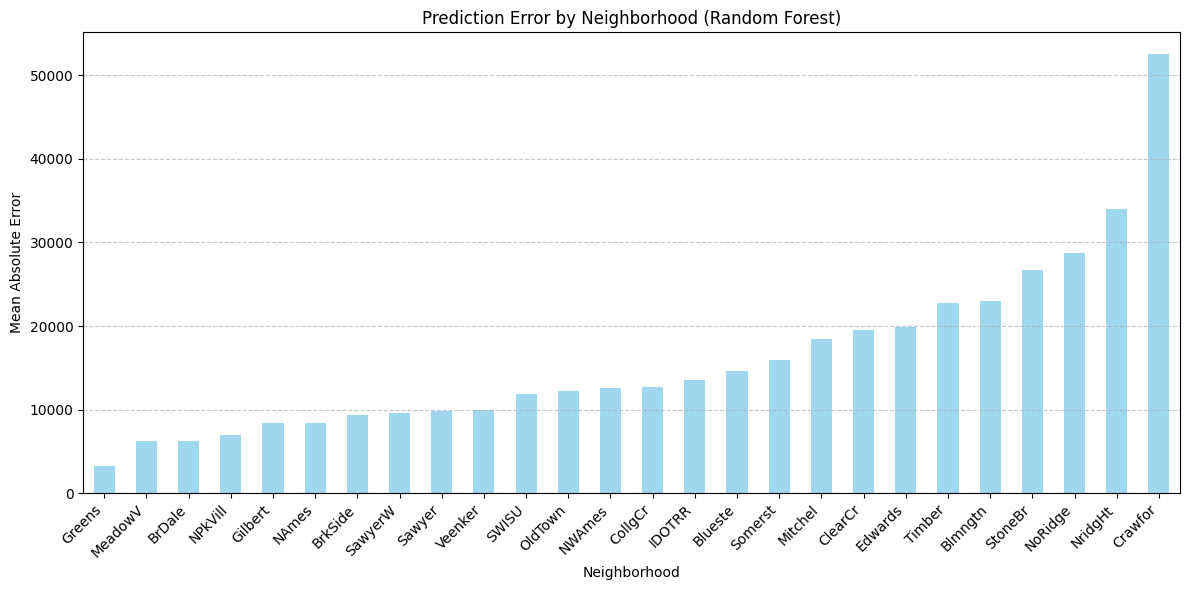

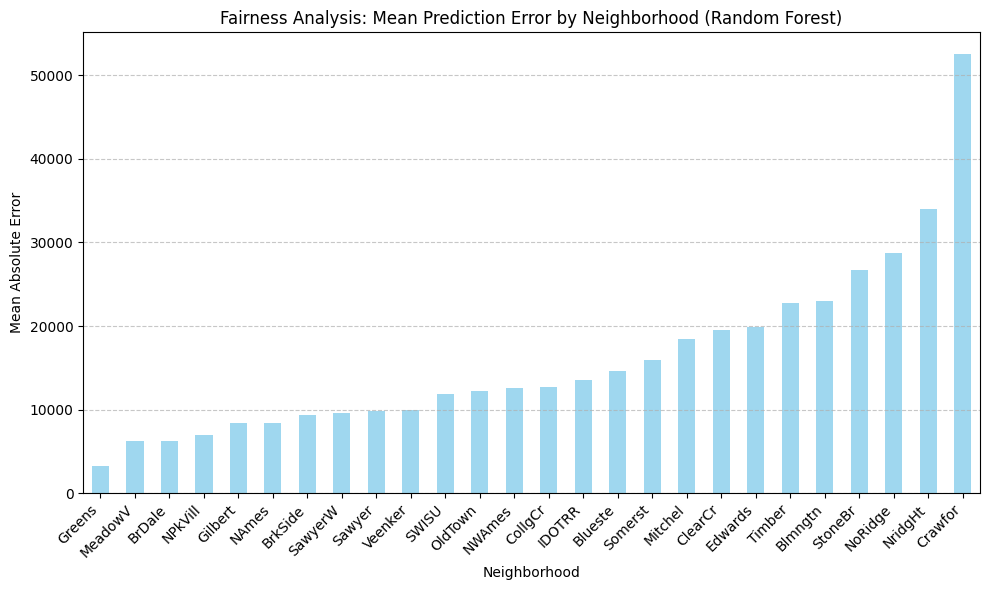

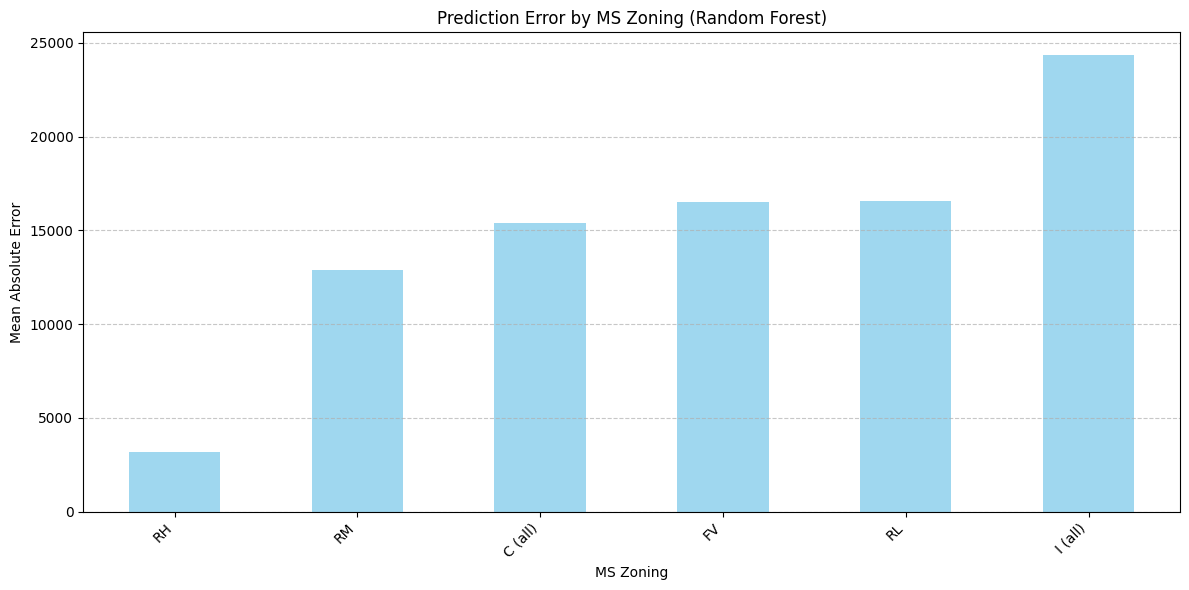

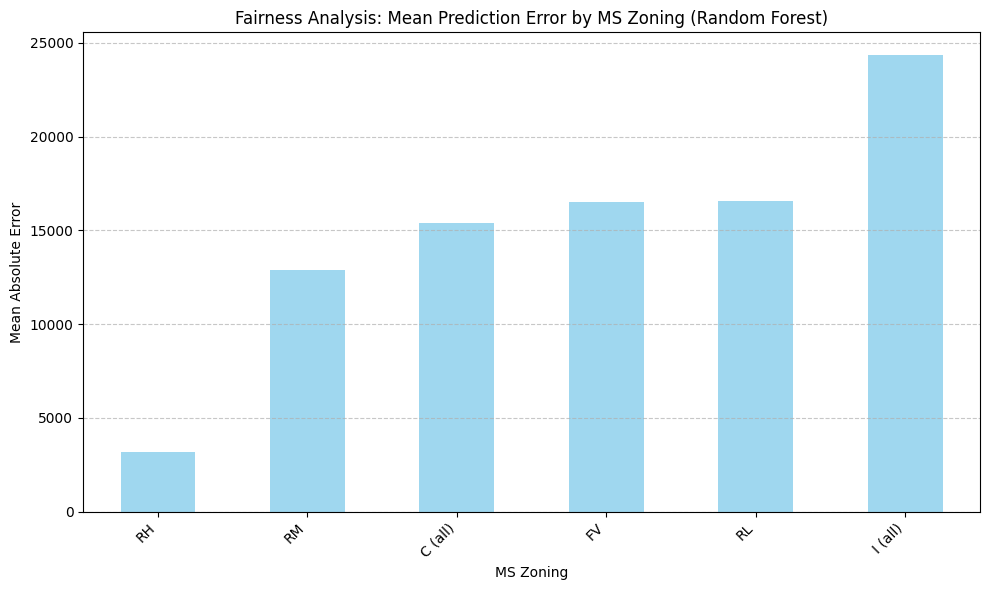

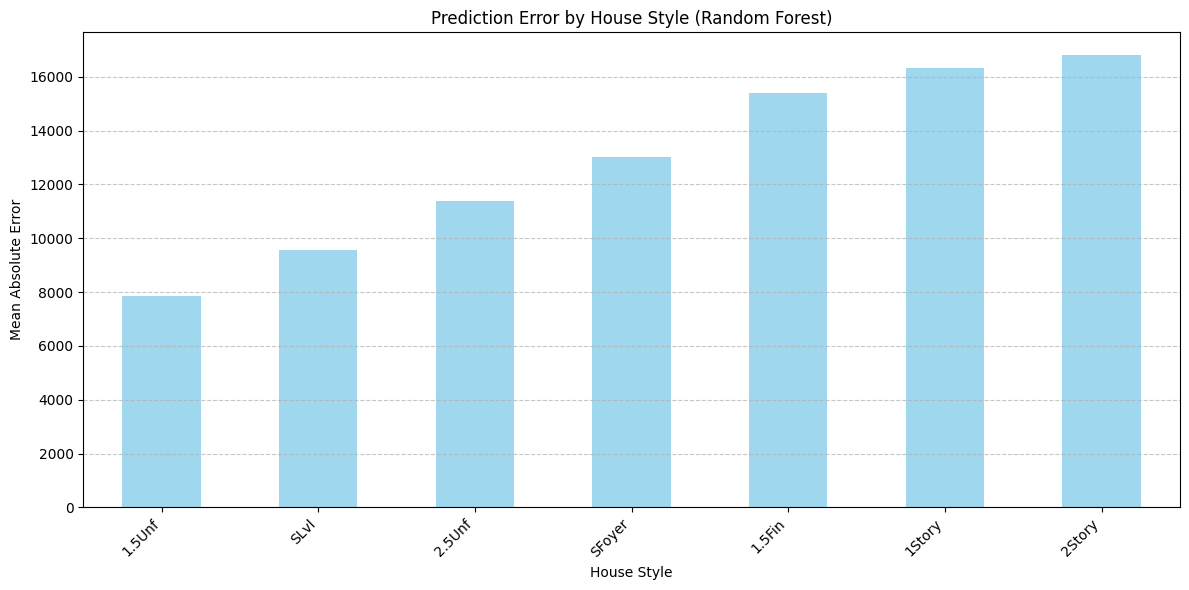

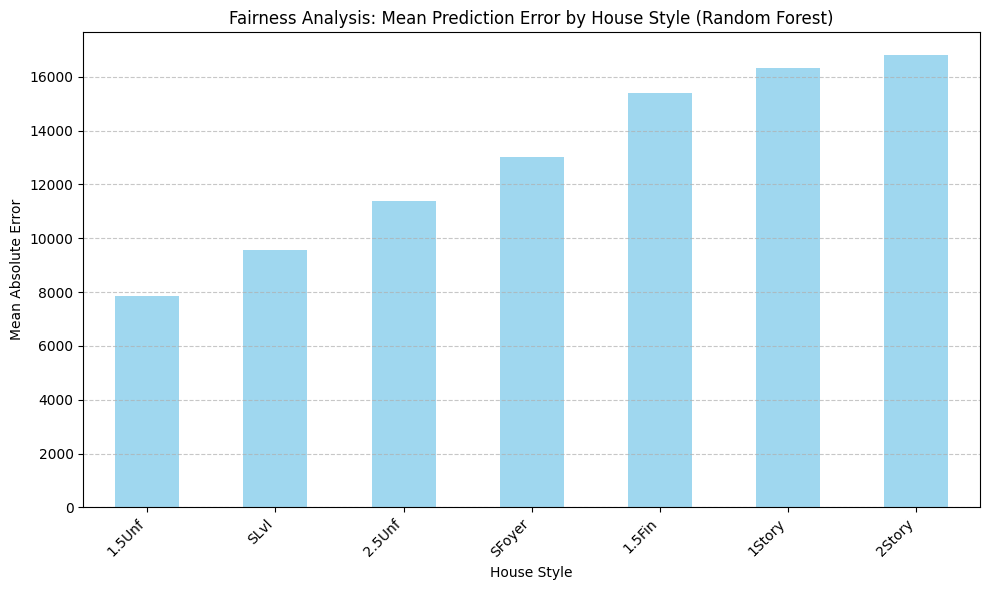

In [ ]:
# Random Forest Analysis
print("Random Forest Analysis")
test_data['RandomForest_Error'] = abs(y_test.values - rf_pred_optimized)
for feature in features_to_analyze:
    analyze_prediction_error(
        feature,
        "Random Forest",
        test_data[[feature, 'RandomForest_Error']].rename(columns={'RandomForest_Error': 'Prediction_Error'})
    )
    evaluate_fairness(feature, rf_pred_optimized, y_test.values, "Random Forest")

XGBoost Analysis


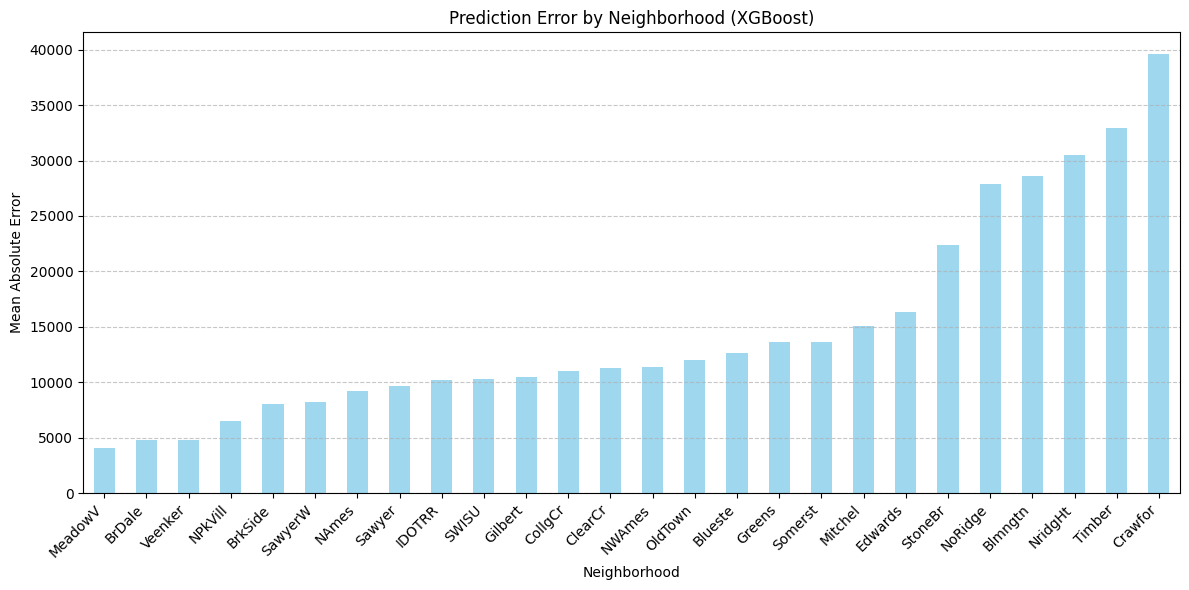

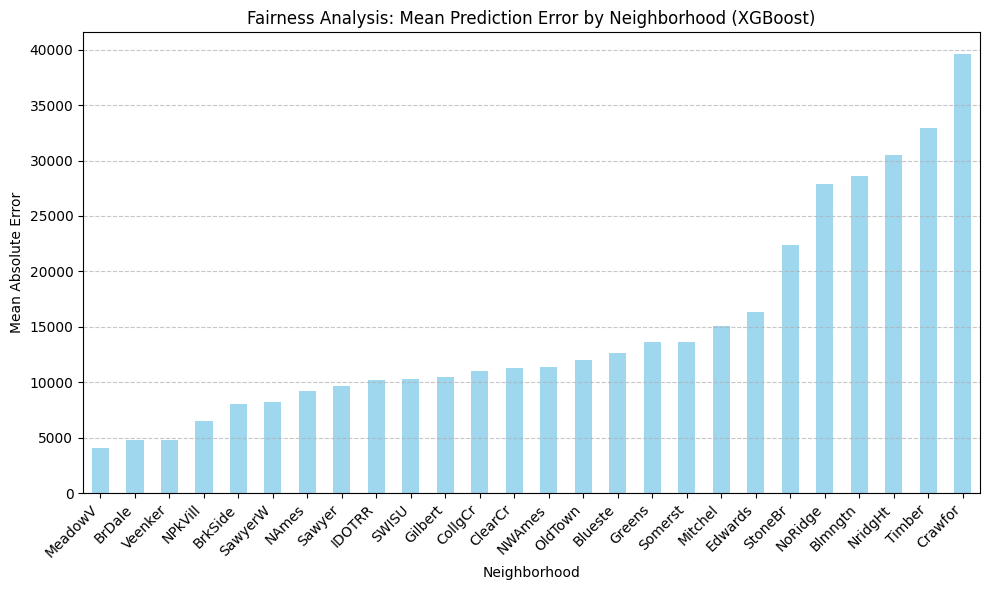

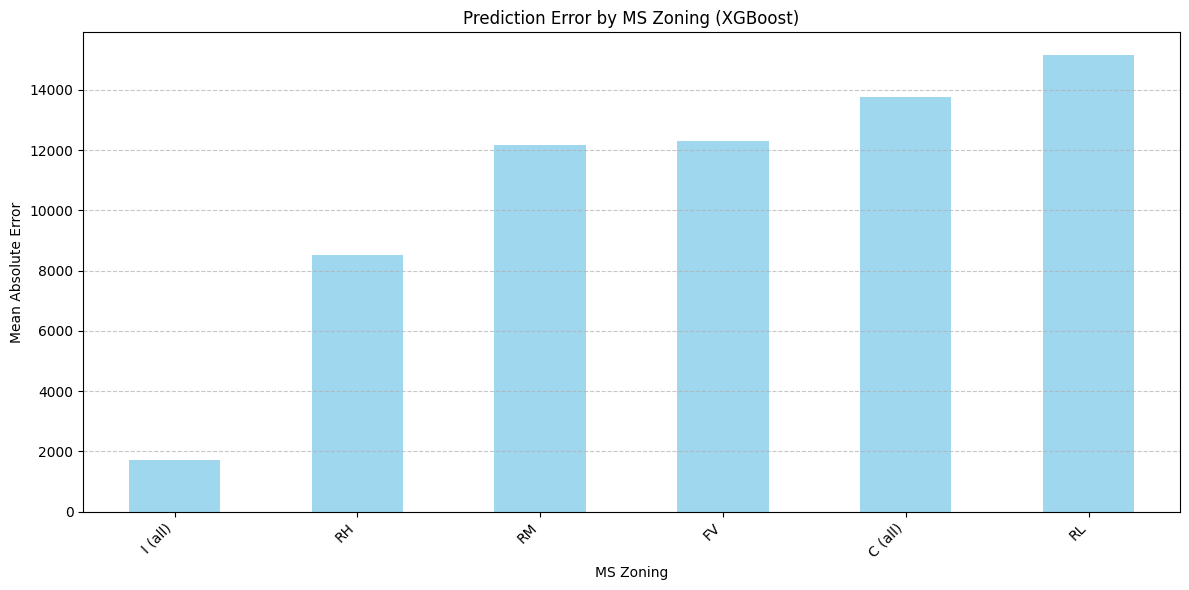

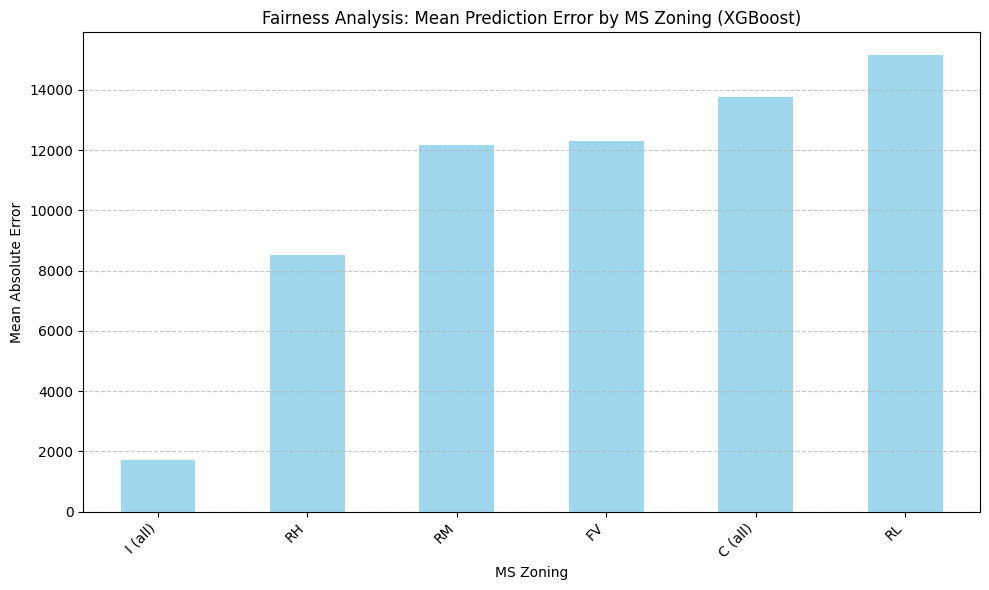

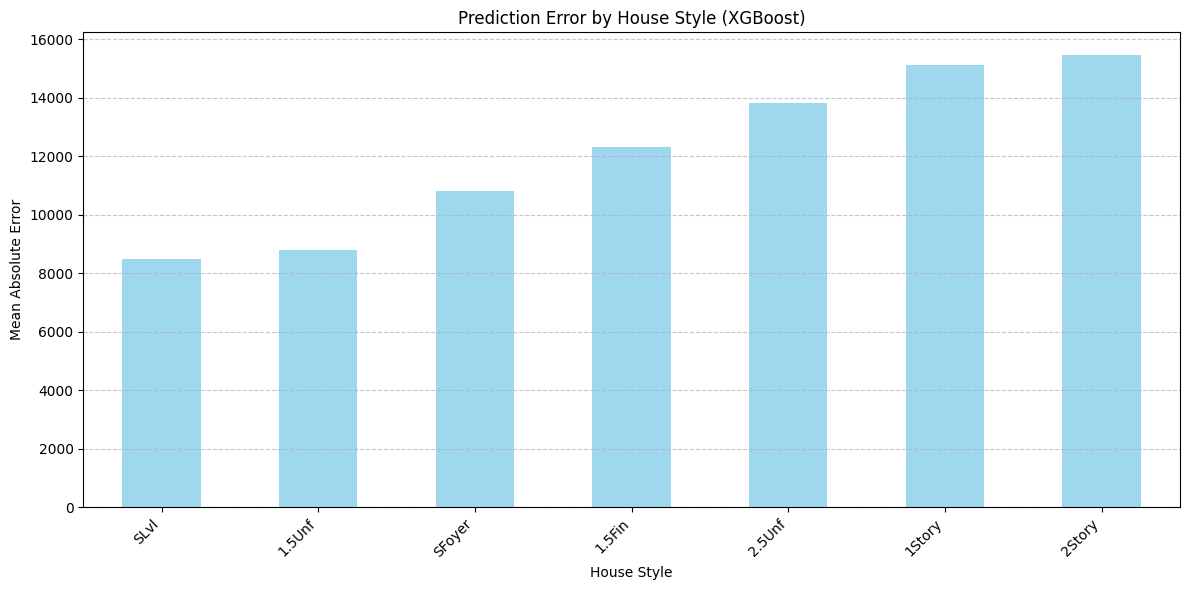

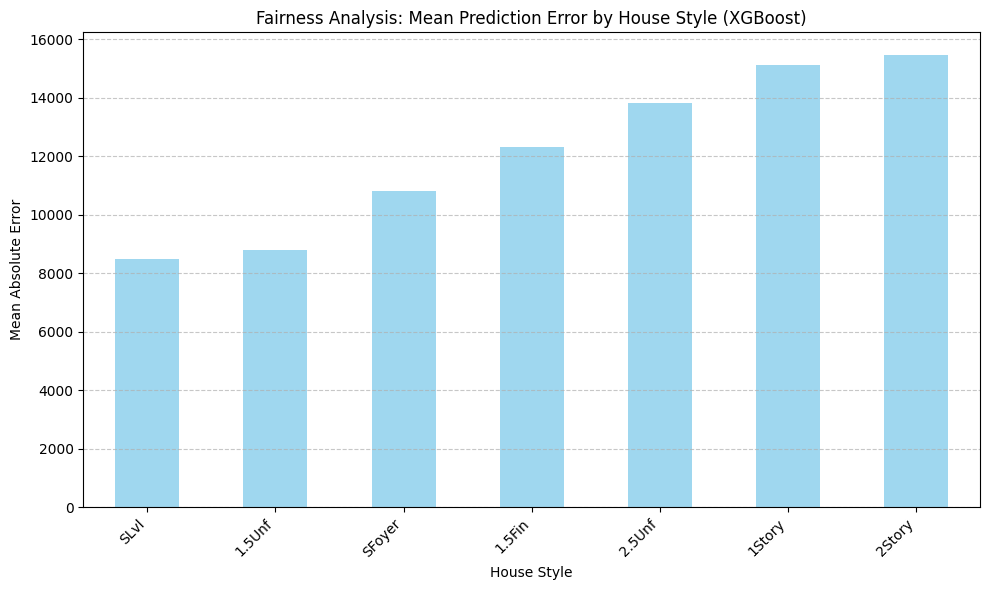

In [27]:
# XGBoost Analysis
print("XGBoost Analysis")
test_data['XGBoost_Error'] = abs(y_test.values - xgb_pred_optimized)
for feature in features_to_analyze:
    analyze_prediction_error(
        feature,
        "XGBoost",
        test_data[[feature, 'XGBoost_Error']].rename(columns={'XGBoost_Error': 'Prediction_Error'})
    )
    evaluate_fairness(feature, xgb_pred_optimized, y_test.values, "XGBoost")



LightGBM Analysis


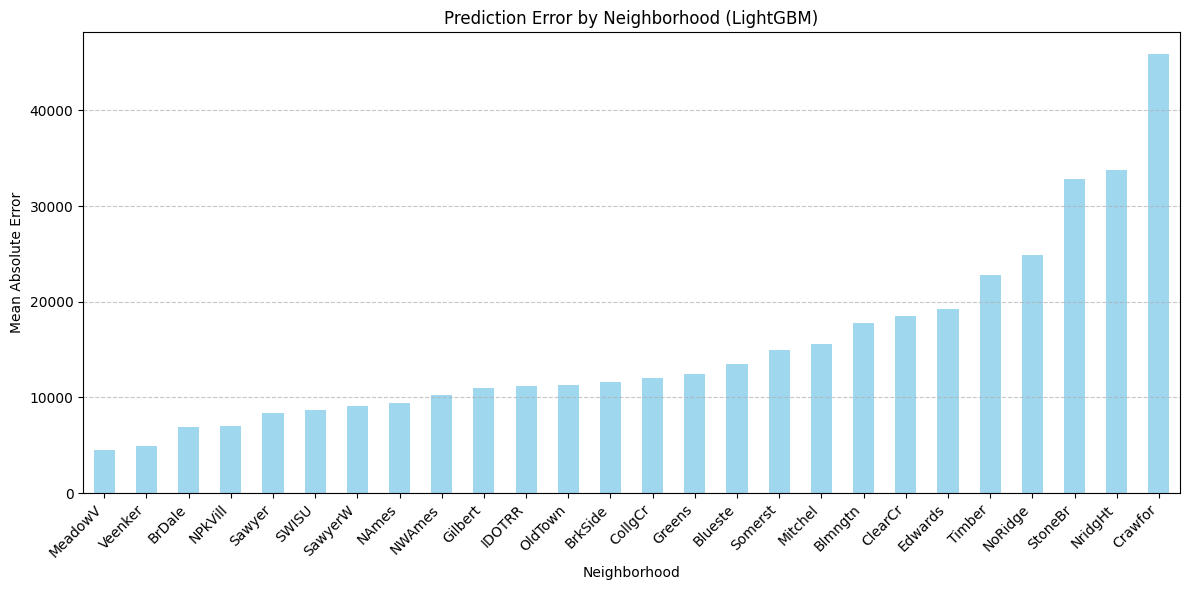

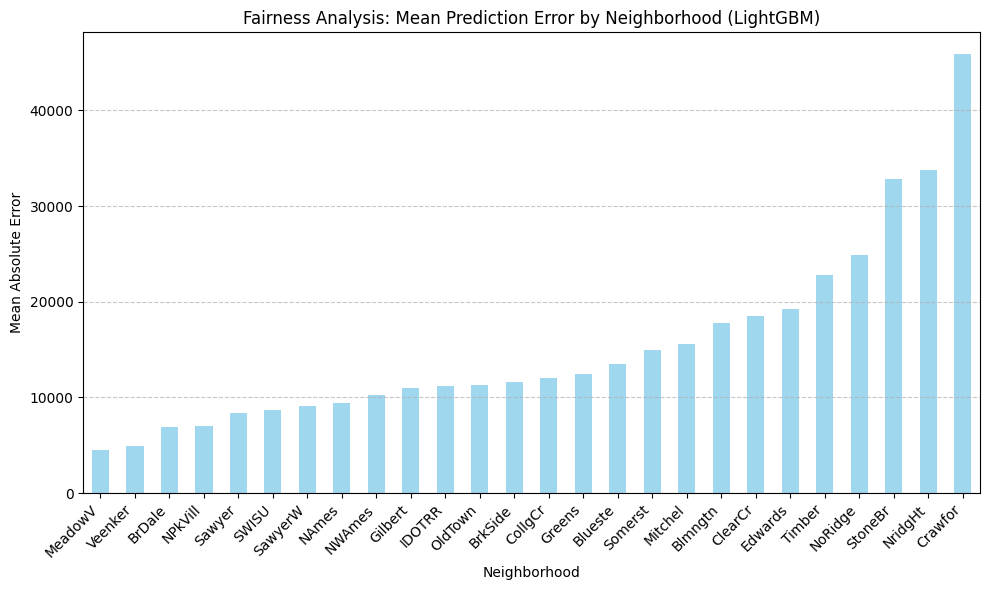

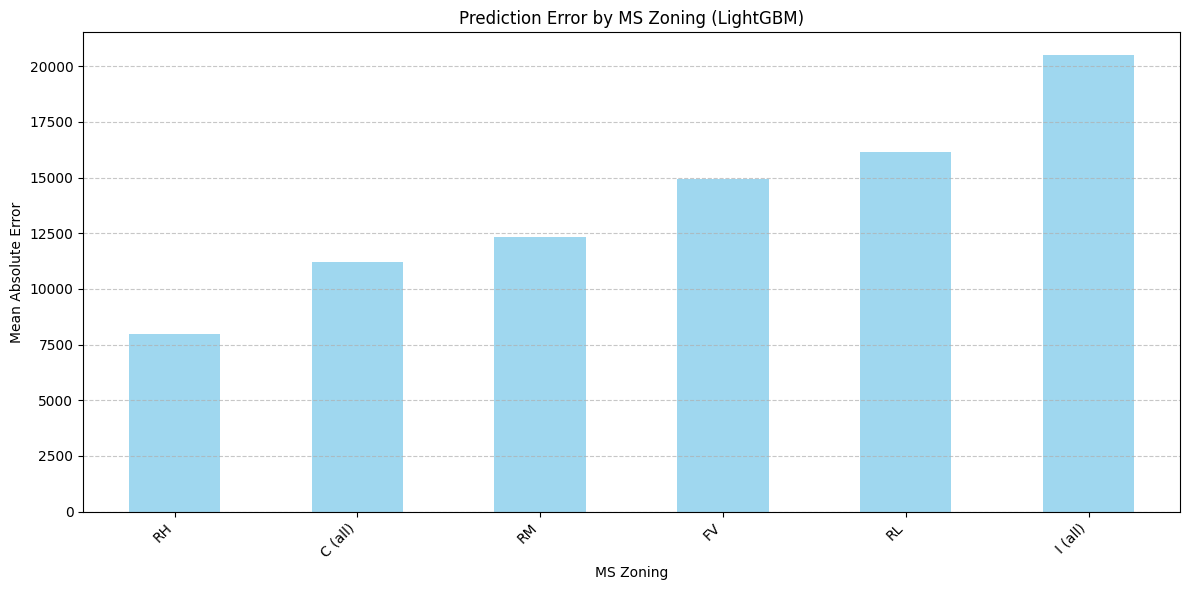

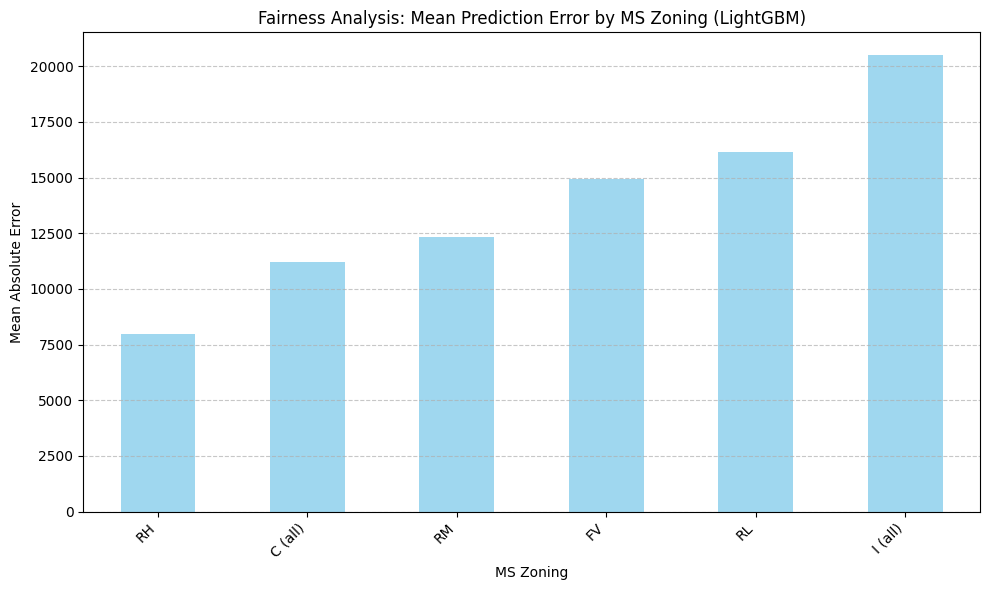

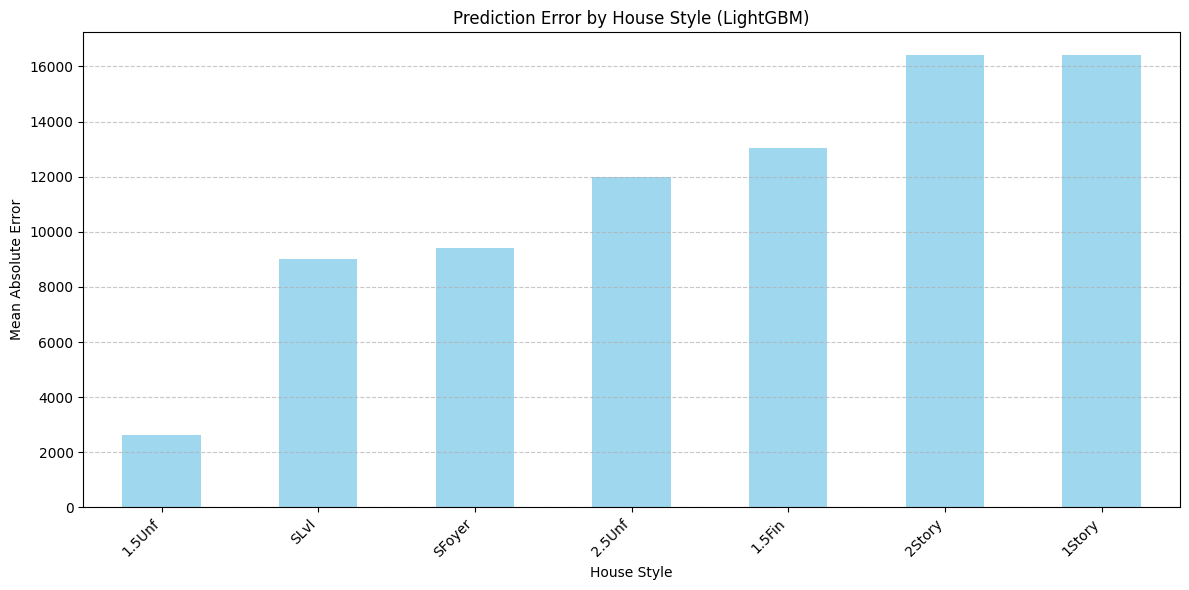

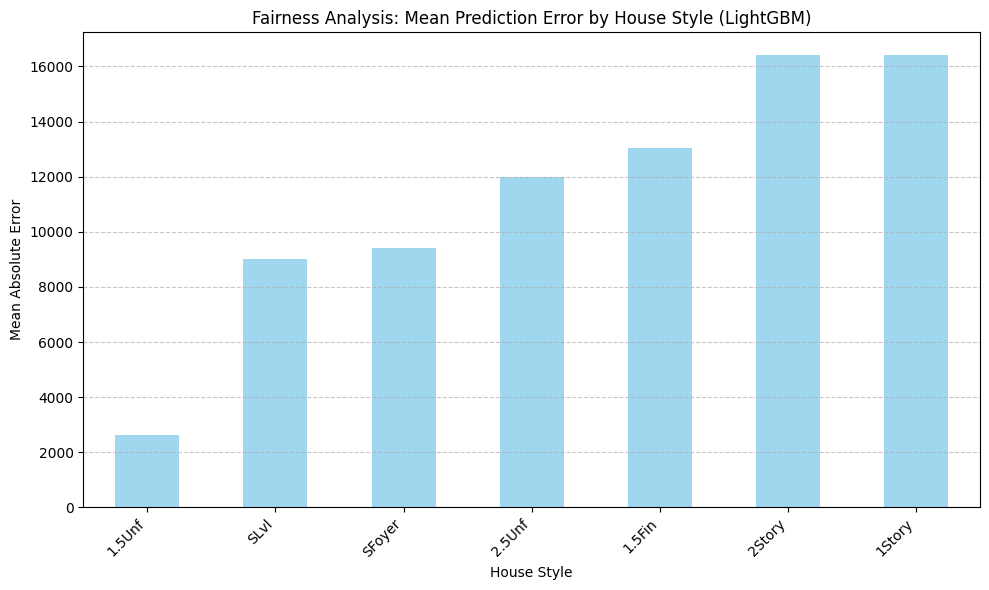

In [28]:
# LightGBM Analysis
print("LightGBM Analysis")
test_data['LightGBM_Error'] = abs(y_test.values - lgb_pred_optimized)
for feature in features_to_analyze:
    analyze_prediction_error(
        feature,
        "LightGBM",
        test_data[[feature, 'LightGBM_Error']].rename(columns={'LightGBM_Error': 'Prediction_Error'})
    )
    evaluate_fairness(feature, lgb_pred_optimized, y_test.values, "LightGBM")